# Plant Disease Detection Using CNN
## Model Implementation and Evaluation

**Objective:** Classify tomato leaf images into four categories using a Convolutional Neural Network (CNN).

Classes: Tomato Bacterial Spot, Tomato Early Blight, Tomato Healthy, and Tomato Late Blight.

This notebook demonstrates dataset loading, preprocessing, CNN architecture, training, evaluation, and saving the model.

**Requirements:** Python, TensorFlow/Keras, NumPy, Matplotlib, scikit-learn.

> **Dataset:** Place your class folders under `data/raw/`, or update `DATASET_DIR` below. Dataset images are not bundled in this notebook.

## 1. Import libraries

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPUs: []


## 2. Configure the dataset

Expected folder structure:

```text
data/raw/
├── Tomato___Bacterial_spot/
├── Tomato___Early_blight/
├── Tomato___healthy/
└── Tomato___Late_blight/
```

In [16]:
from pathlib import Path
import json

# Save to the project's main models folder
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "plant_disease_cnn_notebook.keras"
class_names_path = MODEL_DIR / "class_names_notebook.json"

model.save(model_path)

with open(class_names_path, "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=2)

print("Model saved to:", model_path)
print("Class names saved to:", class_names_path)

Model saved to: c:\Users\sweth\Downloads\Plant_Disease_Detection_CNN_Complete_Project\Plant_Disease_Detection_CNN\models\plant_disease_cnn_notebook.keras
Class names saved to: c:\Users\sweth\Downloads\Plant_Disease_Detection_CNN_Complete_Project\Plant_Disease_Detection_CNN\models\class_names_notebook.json


In [5]:
from pathlib import Path

print("Current directory:", Path.cwd())
print("Available folders:", [p.name for p in Path.cwd().iterdir() if p.is_dir()])

Current directory: c:\Users\sweth\Downloads\Plant_Disease_Detection_CNN_Complete_Project\Plant_Disease_Detection_CNN\notebooks
Available folders: []


## 3. Load and preprocess images

Images are resized to 224 × 224. The dataset is divided into training, validation, and test subsets. Pixel rescaling is included in the model.

In [6]:
train_ds = keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

temp_ds = keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

class_names = train_ds.class_names
num_classes = len(class_names)

# Split the held-out 30% into validation and test sets.
num_batches = int(tf.data.experimental.cardinality(temp_ds).numpy())
if num_batches < 2:
    raise ValueError("Not enough batches to split validation and test data. Add images or reduce BATCH_SIZE.")

val_count = max(1, num_batches // 2)
val_ds = temp_ds.take(val_count)
test_ds = temp_ds.skip(val_count)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Found 6627 files belonging to 4 classes.
Using 4639 files for training.
Found 6627 files belonging to 4 classes.
Using 1988 files for validation.
Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___healthy']
Number of classes: 4


## 4. Visualize sample images

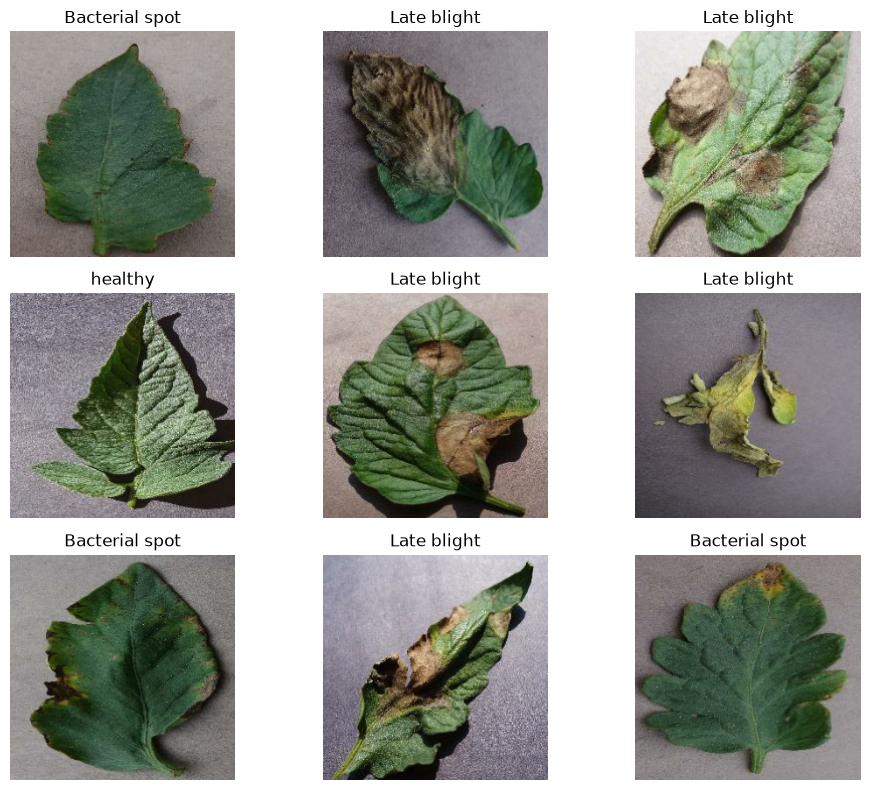

In [7]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])].replace("Tomato___", "").replace("_", " "))
        plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Define the CNN architecture

Convolution layers learn visual features. Max-pooling reduces spatial dimensions, dropout helps reduce overfitting, and softmax produces class probabilities.

In [8]:
model = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,452,740 (13.17 MB)

 Trainable params: 3,452,740 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model

In [9]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/15


c:\Users\sweth\Downloads\Plant_Disease_Detection_CNN_Complete_Project\Plant_Disease_Detection_CNN\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


145/145 ━━━━━━━━━━━━━━━━━━━━ 90s 604ms/step - accuracy: 0.6911 - loss: 0.7583 - val_accuracy: 0.8216 - val_loss: 0.4805
Epoch 2/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 88s 596ms/step - accuracy: 0.8532 - loss: 0.4010 - val_accuracy: 0.8730 - val_loss: 0.3027
Epoch 3/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 89s 600ms/step - accuracy: 0.8952 - loss: 0.2839 - val_accuracy: 0.9062 - val_loss: 0.2468
Epoch 4/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 90s 608ms/step - accuracy: 0.8944 - loss: 0.2956 - val_accuracy: 0.8952 - val_loss: 0.2734
Epoch 5/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 91s 612ms/step - accuracy: 0.9215 - loss: 0.2160 - val_accuracy: 0.8508 - val_loss: 0.3990
Epoch 6/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 92s 618ms/step - accuracy: 0.9202 - loss: 0.2185 - val_accuracy: 0.9204 - val_loss: 0.2367
Epoch 7/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 91s 617ms/step - accuracy: 0.9442 - loss: 0.1574 - val_accuracy: 0.8921 - val_loss: 0.2794
Epoch 8/15
145/145 ━━━━━━━━━━━━━━━━━━━━ 92s 623ms/step - accuracy: 0.9424 - loss: 0.1534 - val

## 7. Plot training history

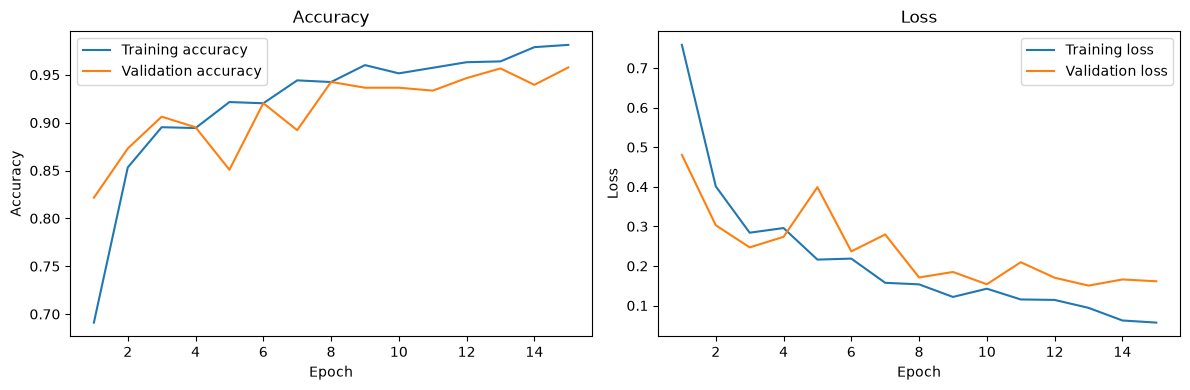

In [10]:
history_dict = history.history
epoch_numbers = range(1, len(history_dict["accuracy"]) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, history_dict["accuracy"], label="Training accuracy")
plt.plot(epoch_numbers, history_dict["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, history_dict["loss"], label="Training loss")
plt.plot(epoch_numbers, history_dict["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 8. Evaluate on the test set

The classification report gives precision, recall, F1-score, and support for each class.

In [11]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

y_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(num_classes)),
    target_names=class_names,
    zero_division=0,
))

32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 160ms/step - accuracy: 0.9739 - loss: 0.1022
Test loss: 0.1022
Test accuracy: 0.9739
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 204ms/step
                         precision    recall  f1-score   support

Tomato___Bacterial_spot       0.27      0.28      0.28       296
  Tomato___Early_blight       0.17      0.17      0.17       156
   Tomato___Late_blight       0.28      0.28      0.28       280
       Tomato___healthy       0.21      0.20      0.21       264

               accuracy                           0.24       996
              macro avg       0.23      0.23      0.23       996
           weighted avg       0.24      0.24      0.24       996



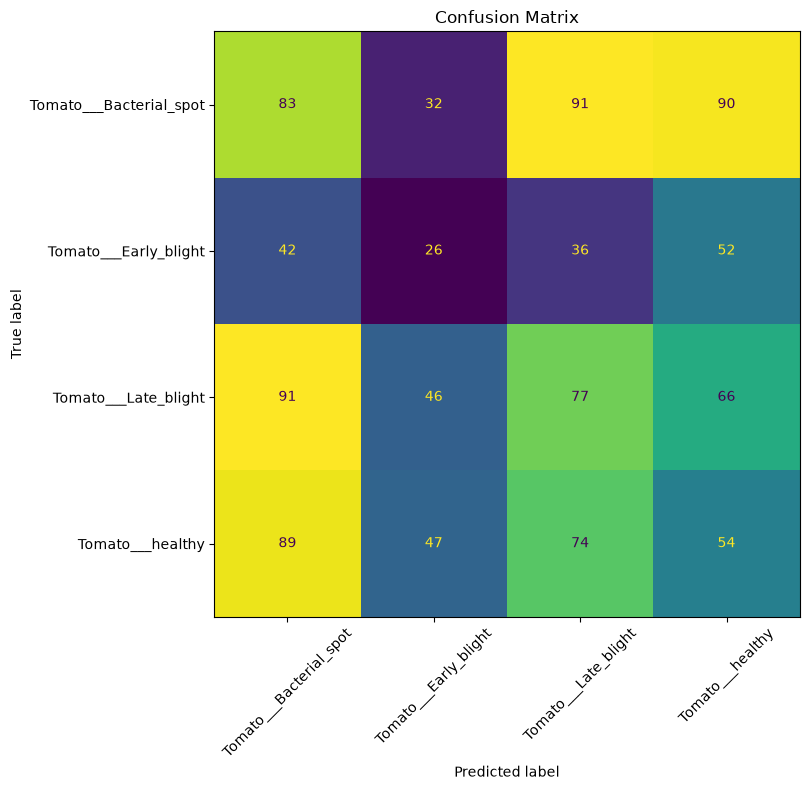

In [12]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(9, 8))
display.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Save the trained model and class names

In [13]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_path = MODEL_DIR / "plant_disease_cnn_notebook.keras"
class_names_path = MODEL_DIR / "class_names_notebook.json"

model.save(model_path)
with open(class_names_path, "w", encoding="utf-8") as file:
    json.dump(class_names, file, indent=2)

print("Model saved to:", model_path.resolve())
print("Class names saved to:", class_names_path.resolve())

Model saved to: C:\Users\sweth\Downloads\Plant_Disease_Detection_CNN_Complete_Project\Plant_Disease_Detection_CNN\notebooks\models\plant_disease_cnn_notebook.keras
Class names saved to: C:\Users\sweth\Downloads\Plant_Disease_Detection_CNN_Complete_Project\Plant_Disease_Detection_CNN\notebooks\models\class_names_notebook.json


## 10. Predict one image

Image: 000146ff-92a4-4db6-90ad-8fce2ae4fddd___GH_HL Leaf 259.1.JPG
Predicted class: Tomato___healthy
Confidence: 100.00%


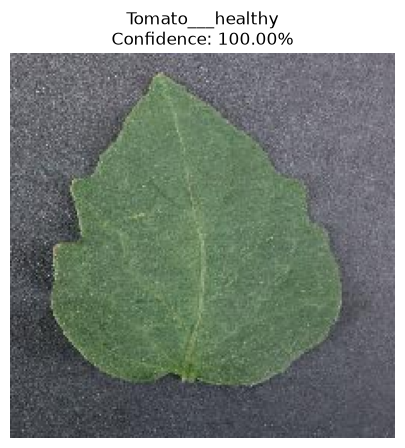

In [15]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

# Select a sample image from the dataset
IMAGE_PATH = next(
    (PROJECT_DIR / "data" / "raw" / "Tomato___healthy").glob("*.JPG"),
    None
)

# Try lowercase extension if uppercase JPG wasn't found
if IMAGE_PATH is None:
    IMAGE_PATH = next(
        (PROJECT_DIR / "data" / "raw" / "Tomato___healthy").glob("*.jpg"),
        None
    )

if IMAGE_PATH is None:
    raise FileNotFoundError("No .JPG or .jpg image found in the healthy folder.")

image = load_img(IMAGE_PATH, target_size=IMG_SIZE)
image_batch = np.expand_dims(img_to_array(image), axis=0)

prediction = model.predict(image_batch, verbose=0)[0]
predicted_index = int(np.argmax(prediction))

print("Image:", IMAGE_PATH.name)
print("Predicted class:", class_names[predicted_index])
print(f"Confidence: {prediction[predicted_index] * 100:.2f}%")

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(
    f"{class_names[predicted_index]}\n"
    f"Confidence: {prediction[predicted_index] * 100:.2f}%"
)
plt.axis("off")
plt.show()

## 11. Conclusion and notes

This notebook demonstrates the complete CNN workflow: image loading, preprocessing, model definition, training, evaluation, visualization, saving, and single-image prediction.

**Important:** This is a self-contained model implementation for evaluator review. Training it creates a new model and does not automatically reproduce the exact trained weights already used by the deployed app. For reproducible results, use the same dataset, architecture, preprocessing, and training configuration as the original project.